# Titanic Survival Prediction — Logistic Regression
**Type of problem:** Supervised learning → *Classification* (target `Survived` is 0/1, not a continuous number).

**Payments analogy:** This is the same idea as fraud/failure prediction on a transaction — look at past outcomes (labelled data), learn the pattern, predict the outcome for new ones.

Same recipe as the Linear Regression session: **Look → Clean → Split → Train → Evaluate → Explain → Predict.**

## 1. Explore the Raw Data

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('train.csv')

print("Shape:", df.shape)
print("\nFirst look:\n", df.head())
print("\nNull values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
df.info()

Shape: (891, 12)

First look:
    PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            3734

In [2]:
display(df.describe())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**What we see:**
- `Age` has missing values, `Cabin` is mostly empty (~77%), `Embarked` has 2 blanks.
- `PassengerId`, `Name`, `Ticket` are identifiers — no predictive value.
- Target = `Survived`. Everything else = possible inputs (features).

### Quick look at the pattern (before modelling)
Always peek at the target vs. key columns — like checking failure % by channel (UPI / NEFT / RTGS) before building anything.

In [3]:
print("Overall survival rate:", round(df['Survived'].mean()*100, 1), "%")
print("\nSurvival rate by Sex:\n", (df.groupby('Sex')['Survived'].mean()*100).round(1))
print("\nSurvival rate by Class:\n", (df.groupby('Pclass')['Survived'].mean()*100).round(1))

Overall survival rate: 38.4 %

Survival rate by Sex:
 Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Survival rate by Class:
 Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


## 2. Data Cleaning

### Step 1 — Check duplicate rows (BEFORE dropping the ID)
Order matters here. With `PassengerId` still present, every row is unique. If we dropped the ID first, 2 different passengers with the same class/sex/age/fare would look like "duplicates" and we would wrongly delete real people. 
Same as a payment file: two txns with the same amount and beneficiary but different RRNs are **not** duplicates.

In [4]:
print(f"Rows before: {len(df)}")
print("True duplicates (ID included):", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print(f"Rows after : {len(df)}")

Rows before: 891
True duplicates (ID included): 0
Rows after : 891


### Step 2 — Drop useless columns
`PassengerId`, `Name`, `Ticket` = identifiers (like a txn ID — no pattern in it).
`Cabin` = ~77% empty; filling it would mean inventing most of the data.

In [5]:
df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)
print("Remaining columns:", df.columns.tolist())

Remaining columns: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


### Step 3 — Fill missing values
- `Age` (number) → **median** (not affected by extreme ages).
- `Embarked` (category) → **most frequent value (mode)**. Median makes no sense for text.

In [6]:
print("Nulls before:\n", df[['Age', 'Embarked']].isnull().sum())

median_age = df['Age'].median()
df['Age'] = df['Age'].fillna(median_age)
print(f"\nFilled Age with median: {median_age}")

mode_embarked = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(mode_embarked)
print(f"Filled Embarked with most common port: {mode_embarked}")

print("\nNulls after:\n", df[['Age', 'Embarked']].isnull().sum())

Nulls before:
 Age         177
Embarked      2
dtype: int64

Filled Age with median: 28.0
Filled Embarked with most common port: S

Nulls after:
 Age         0
Embarked    0
dtype: int64


### Step 4 — Check outliers in `Fare` (IQR) — and decide
IQR is a tool, not an order. Check first, then *think*.

In [7]:
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Upper bound: {upper_bound:.2f}")
n_out = (df['Fare'] > upper_bound).sum()
print(f"Rows above the upper bound: {n_out} ({n_out/len(df)*100:.1f}% of data)")
print("\nWho are they?\n", df[df['Fare'] > upper_bound]['Pclass'].value_counts())

Q1: 7.91 | Q3: 31.00 | IQR: 23.09
Upper bound: 65.63
Rows above the upper bound: 116 (13.0% of data)

Who are they?
 Pclass
1    104
3      7
2      5
Name: count, dtype: int64


**Decision: we KEEP them.** These are mostly 1st-class passengers with genuinely expensive tickets — real data, not errors (unlike the ₹99,99,999 salary in the HR dataset, which was a typo-type value). Removing them would delete a whole passenger group. 
*Rule: remove an outlier only if it is an error. Keep it if it is rare-but-real.*

### Step 5 — Encode text columns (One-Hot Encoding)
`Sex` and `Embarked` are text. The model only understands numbers.

In [8]:
df = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True)
print("Columns after encoding:", df.columns.tolist())
display(df.head())

Columns after encoding: ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


`Sex_male = 1` means male, `0` means female. `Embarked_Q`, `Embarked_S` = both 0 means Cherbourg (the dropped base case).

## 3. Features, Target & Train-Test Split

In [9]:
from sklearn.model_selection import train_test_split

X = df.drop('Survived', axis=1)   # inputs
y = df['Survived']                # what we want to predict

# 80% train / 20% test. stratify=y keeps the same survived/died ratio in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Survival rate in train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

X_train: (712, 8) | X_test: (179, 8)
Survival rate in train: 0.383 | test: 0.385


## 4. Build the Model — Logistic Regression
**Why not Linear Regression?** Linear Regression outputs any number (₹86,692). Here we need a **Yes/No**. 
Logistic Regression outputs a *probability* (0 to 1); above 0.5 → predicts `1` (survived).

In [10]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)   # same 3 steps as before
model.fit(X_train, y_train)                 # train
y_pred = model.predict(X_test)              # predict

print("First 10 predictions:", y_pred[:10])
print("First 10 actual     :", y_test.values[:10])

First 10 predictions: [0 0 0 0 1 0 1 0 0 0]
First 10 actual     : [0 0 1 0 1 1 1 0 0 0]


## 5. Evaluate the Model

For classification we use **Accuracy** (and not R²/MAE/RMSE — those are for numbers).
We also compare against a **baseline** — if a model can't beat a dumb guess, it's useless.

In [11]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, y_pred)
baseline = 1 - y_test.mean()   # dumb model: "everyone died"

print(f"Model accuracy        : {accuracy*100:.2f}%")
print(f"Baseline (all died)   : {baseline*100:.2f}%")
print(f"Improvement over dumb : {(accuracy-baseline)*100:.2f} points\n")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nDetailed report:\n", classification_report(y_test, y_pred, target_names=['Died', 'Survived']))

Model accuracy        : 80.45%
Baseline (all died)   : 61.45%
Improvement over dumb : 18.99 points

Confusion Matrix:
 [[98 12]
 [23 46]]

Detailed report:
               precision    recall  f1-score   support

        Died       0.81      0.89      0.85       110
    Survived       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



**Reading the confusion matrix** (like reconciliation):
| | Predicted Died | Predicted Survived |
|---|---|---|
| **Actually Died** | Correct ✅ | False alarm ❌ |
| **Actually Survived** | Missed ❌ | Correct ✅ |

## 6. Visualise Results

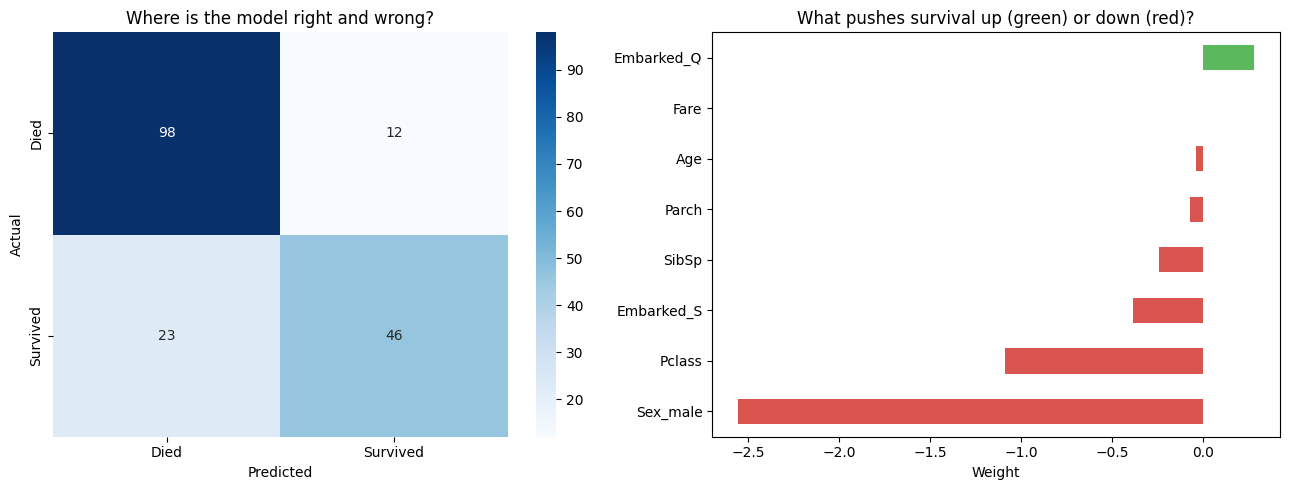

Sex_male     -2.56
Pclass       -1.09
Embarked_S   -0.38
SibSp        -0.24
Parch        -0.07
Age          -0.04
Fare          0.00
Embarked_Q    0.28
dtype: float64


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Confusion matrix
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Died', 'Survived'], yticklabels=['Died', 'Survived'], ax=ax[0])
ax[0].set_title('Where is the model right and wrong?')
ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')

# Plot 2: What drives the prediction (model weights)
weights = pd.Series(model.coef_[0], index=X.columns).sort_values()
weights.plot(kind='barh', color=['#d9534f' if w < 0 else '#5cb85c' for w in weights], ax=ax[1])
ax[1].set_title('What pushes survival up (green) or down (red)?')
ax[1].set_xlabel('Weight')

plt.tight_layout()
plt.show()

print(weights.round(2))

## 7. Business Insight
- **Gender was the strongest factor:** being male sharply reduced survival odds ("women and children first").
- **Class mattered:** moving from 1st → 3rd class reduced survival odds — ticket class acted as a proxy for deck location and priority access to lifeboats.
- **Age:** younger passengers had a slightly better chance.
- **Honest limitation:** The model uses a straight-line relationship and ignores combinations (e.g. *a 3rd-class woman travelling alone*). Names (titles like Mrs/Master), family size and cabin deck carry extra signal not used here. Accuracy on a single 20% split can also move a few points with a different split — so treat it as an estimate, not a guarantee.

## 8. Kaggle Submission (predict the 418 unseen passengers)
**Golden rule:** the test file must be cleaned *exactly* like train — and with values learned from **train** (median age, most common port). Like applying the same validation rules to every new batch.

In [13]:
test = pd.read_csv('test.csv')
passenger_ids = test['PassengerId']          # keep for the submission file

# --- same cleaning steps as train ---
test.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)
test['Age'] = test['Age'].fillna(median_age)             # train's median
test['Embarked'] = test['Embarked'].fillna(mode_embarked)
test['Fare'] = test['Fare'].fillna(df['Fare'].median())  # test has 1 missing Fare
test = pd.get_dummies(test, columns=['Sex', 'Embarked'], drop_first=True)

# make sure test has the SAME columns in the SAME order as training
test = test.reindex(columns=X.columns, fill_value=0)

print("Nulls left in test:", test.isnull().sum().sum())
print("Test shape:", test.shape)

Nulls left in test: 0
Test shape: (418, 8)


In [14]:
# Retrain on 100% of the labelled data, then predict the test set
final_model = LogisticRegression(max_iter=1000)
final_model.fit(X, y)

submission = pd.DataFrame({
    'PassengerId': passenger_ids,
    'Survived': final_model.predict(test)
})
submission.to_csv('submission.csv', index=False)

print("Rows in submission:", len(submission), "(Kaggle needs 418)")
print("Predicted survival rate:", round(submission['Survived'].mean()*100, 1), "%")
display(submission.head())

Rows in submission: 418 (Kaggle needs 418)
Predicted survival rate: 37.1 %


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


## 9. Dynamic Prediction — one passenger

In [15]:
def predict_passenger(pclass, sex, age, sibsp, parch, fare, embarked):
    """sex: 'male'/'female' | embarked: 'C', 'Q' or 'S'"""
    row = pd.DataFrame([{
        'Pclass': pclass, 'Age': age, 'SibSp': sibsp, 'Parch': parch, 'Fare': fare,
        'Sex_male': int(sex == 'male'),
        'Embarked_Q': int(embarked == 'Q'),
        'Embarked_S': int(embarked == 'S'),
    }])[X.columns]
    prob = final_model.predict_proba(row)[0][1]
    print(f"{sex}, age {age}, class {pclass} -> survival chance: {prob*100:.1f}% "
          f"=> {'SURVIVED' if prob >= 0.5 else 'DIED'}")

predict_passenger(pclass=1, sex='female', age=30, sibsp=0, parch=0, fare=80, embarked='C')
predict_passenger(pclass=3, sex='male',   age=25, sibsp=0, parch=0, fare=8,  embarked='S')
predict_passenger(pclass=2, sex='male',   age=6,  sibsp=1, parch=1, fare=25, embarked='S')

female, age 30, class 1 -> survival chance: 95.3% => SURVIVED
male, age 25, class 3 -> survival chance: 11.0% => DIED
male, age 6, class 2 -> survival chance: 34.1% => DIED
